# Introduction to the data class

`ProteinDataset` is an ordinary `torch.utils.data.Dataset` over one of the CSVs in `data/`. It
tokenises every sequence once, when it is constructed, and serves both of the project's targets
from the same `x`:

| Item | Shape | What it is |
|---|---|---|
| `x` | `(129,)` long | `<BOS>`, the residues, `<EOS>`, then `<PAD>` |
| `x_shifted` | `(129,)` long | `x` shifted left by one: the next-token target, `-1` past the end |
| `y` | scalar long | the family, as a class index |
| `length` | int | the number of residues, without the special tokens |


In [23]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

## The vocabulary

The token ids are fixed in `protgen.data`, not inferred from the data, so an id means the same
residue in every run and checkpoint: `<PAD>` 0, `<BOS>` 1, `<EOS>` 2, then the 20 standard
residues in alphabetical order. `encode` and `decode` go between a residue string and a token
tensor, and `decode` drops the special tokens - so decoding either `x` or `x_shifted` gives the
protein back.

In [24]:
from protgen.data import AA, FAMILIES, IGNORE_INDEX, special_tokens

print(f"vocab ({train_data.vocab_size} tokens): {train_data.vocab}")
print(f"families: {train_data.fam_to_idx}")
print(f"padding is ignored in the loss with ignore_index={IGNORE_INDEX}")

sequence = train_data.df["sequence"][0]
tokens = train_data.encode(sequence)
print()
print(f"encode / decode round-trips: {train_data.decode(tokens) == sequence}")
print(f"and from the shifted target too:  {train_data.decode(x_shifted) == sequence}")

vocab (23 tokens): {'<PAD>': 0, '<BOS>': 1, '<EOS>': 2, 'A': 3, 'C': 4, 'D': 5, 'E': 6, 'F': 7, 'G': 8, 'H': 9, 'I': 10, 'K': 11, 'L': 12, 'M': 13, 'N': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'V': 20, 'W': 21, 'Y': 22}
families: {'AcyP': 0, 'HPr': 1, 'HU': 2}
padding is ignored in the loss with ignore_index=-1

encode / decode round-trips: True
and from the shifted target too:  True


## The two tasks

Both losses read the same `x`. The generative one predicts every residue from the ones before it,
with `ignore_index` making the padding free of loss; the classification one predicts the family of
the whole sequence. Stand-ins for the logits below, since the model is yours to write.

In [25]:
import torch
import torch.nn.functional as F

x, x_shifted, y, length = next(iter(train_loader))
print(f"batch: x {tuple(x.shape)} {x.dtype}, x_shifted {tuple(x_shifted.shape)}, y {tuple(y.shape)}")

# Generative: one distribution over the vocabulary per position.
logits_gen = torch.randn(x.shape[0], train_data.vocab_size, train_data.max_length)
print(f"generative loss:     {F.cross_entropy(logits_gen, x_shifted, ignore_index=IGNORE_INDEX):.4f}")

# Classification: one distribution over the three families per sequence.
logits_fam = torch.randn(x.shape[0], len(FAMILIES))
print(f"classification loss: {F.cross_entropy(logits_fam, y):.4f}")

batch: x (32, 129) torch.int64, x_shifted (32, 129), y (32,)
generative loss:     3.5814
classification loss: 1.3219


In [26]:
x_shifted

tensor([[13, 17, 11,  ..., -1, -1, -1],
        [13, 14, 11,  ..., -1, -1, -1],
        [13,  6,  5,  ..., -1, -1, -1],
        ...,
        [13,  3,  5,  ..., -1, -1, -1],
        [13,  8,  6,  ..., -1, -1, -1],
        [13, 14, 11,  ..., -1, -1, -1]])

## Next

Write your model in `src/protgen/models/`, and have your sampling code write a CSV with a
`sequence` column to `results/sequences/<name>.csv`. That is the only thing the evaluation asks
for:

```bash
uv run python eval/eval.py --samples results/sequences/mock_data.csv
```

`results/sequences/mock_data.csv` ships with the repo, so that command runs today. See
[`eval/README.md`](../eval/README.md) for what the numbers mean, and make the controls
(`eval/make_controls.py`) before reading any of them.

## LSTM

Batched LSTM. Token ids in, right-shift, cross-entropy on the next token.

MyRecurrentNet(
  (embedding): Embedding(23, 50)
  (lstm): LSTM(50, 50, batch_first=True)
  (l_out): Linear(in_features=50, out_features=23, bias=False)
)
Epoch 0, training loss: 2.5902979373931885, validation loss: 3.1346375942230225

Input sequence:
['<BOS>', 'M', 'E', 'R', 'V', 'T', 'A', 'V', 'A', 'R', 'G', 'R', 'V', 'Q', 'G', 'V', 'G', 'Y', 'R', 'Y', 'Y', 'V', 'S', 'E', 'C', 'A', 'H', 'A', 'T', 'G', 'I', 'H', 'G', 'W', 'V', 'K', 'N', 'E', 'P', 'D', 'G', 'T', 'V', 'R', 'I', 'V', 'A', 'E', 'S', 'S', 'P', 'A', 'A', 'L', 'D', 'D', 'F', 'I', 'R', 'L', 'A', 'H', 'A', 'R', 'N', 'D', 'P', 'V', 'I', 'R', 'V', 'D', 'E', 'I', 'T', 'V', 'E', 'K', 'G', 'Q', 'A', 'T', 'G', 'E', 'F', 'H', 'G', 'F', 'R', 'V', 'S', 'W']

Target sequence:
['M', 'E', 'R', 'V', 'T', 'A', 'V', 'A', 'R', 'G', 'R', 'V', 'Q', 'G', 'V', 'G', 'Y', 'R', 'Y', 'Y', 'V', 'S', 'E', 'C', 'A', 'H', 'A', 'T', 'G', 'I', 'H', 'G', 'W', 'V', 'K', 'N', 'E', 'P', 'D', 'G', 'T', 'V', 'R', 'I', 'V', 'A', 'E', 'S', 'S', 'P', 'A', 'A', 'L',

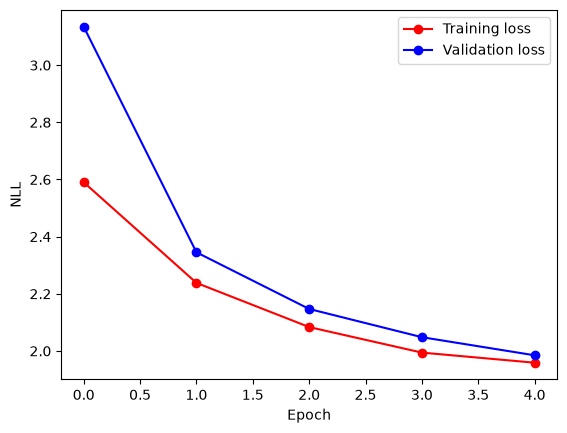

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn

from protgen.models import MyRecurrentNet

# Project vocabulary plays the role of word_to_idx in the course exercise.
word_to_idx = train_data.vocab
idx_to_word = {idx: token for token, idx in word_to_idx.items()}
vocab_size = train_data.vocab_size

from torch.utils.data import DataLoader
from protgen.data import IGNORE_INDEX

# batches of 30
train_loader = DataLoader(train_data, batch_size=30, shuffle=True)
val_loader = DataLoader(val_data, batch_size=30, shuffle=False)

# Hyper-parameters
num_epochs = 5

# Initialize a new network
net = MyRecurrentNet()
print(net)

# Define a loss function and optimizer for this problem
# cross-entropy, ignore pads
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

# Track loss
training_loss, validation_loss = [], []

# For each epoch
for i in range(num_epochs):

    # Track loss
    epoch_training_loss = 0
    epoch_validation_loss = 0

    net.eval()

    # For each batch in the validation set
    with torch.no_grad():
        for x, x_shifted, y, length in val_loader:

            # next-token loss, skip the start step
            logits = net(x)
            loss = criterion(logits[:, 1:].transpose(1, 2), x_shifted[:, :-1])

            # Update loss
            epoch_validation_loss += loss.detach().numpy()

    net.train()

    # For each batch in the training set
    for x, x_shifted, y, length in train_loader:

        # next-token loss, skip the start step
        logits = net(x)
        loss = criterion(logits[:, 1:].transpose(1, 2), x_shifted[:, :-1])

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Update loss
        epoch_training_loss += loss.detach().numpy()

    # Save loss for plot
    training_loss.append(epoch_training_loss/len(train_loader))
    validation_loss.append(epoch_validation_loss/len(val_loader))

    # Print loss every 10 epochs
    if i % 10 == 0:
        print(f'Epoch {i}, training loss: {training_loss[-1]}, validation loss: {validation_loss[-1]}')


# One test protein, as a batch of 1
x, x_shifted, y, length = test_data[1]
n = length + 1
x = x.unsqueeze(0)
x_shifted = x_shifted.unsqueeze(0)

# pick the token with the highest score
logits = net(x)
pred_ids = logits[0, 1:n+1].argmax(dim=-1)

print('\nInput sequence:')
print([idx_to_word[int(token)] for token in x[0, :n]])

print('\nTarget sequence:')
print([idx_to_word[int(token)] for token in x_shifted[0, :n]])

print('\nPredicted sequence:')
print([idx_to_word[int(token)] for token in pred_ids])

# Plot training and validation loss
epoch = np.arange(len(training_loss))
plt.figure()
plt.plot(epoch, training_loss, 'ro-', label='Training loss',)
plt.plot(epoch, validation_loss, 'bo-', label='Validation loss')
plt.legend()
plt.xlabel('Epoch'), plt.ylabel('NLL')
plt.show()


In [28]:
# sample new proteins from the trained net, one residue at a time
from pathlib import Path
import pandas as pd

PAD, BOS, EOS = 0, 1, 2
n_samples = 32
max_len = 80
out_path = Path("../results/sequences/LSTM.csv")

def sample_one(model):
    tokens = [BOS]
    for _ in range(max_len):
        # dummy pad so the last score is the next residue
        inp = torch.tensor([tokens + [PAD]])
        logits = model(inp)[0, -1].clone()
        logits[PAD] = -1e9
        logits[BOS] = -1e9
        nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1).item()
        if nxt == EOS:
            break
        tokens.append(nxt)
    return "".join(idx_to_word[t] for t in tokens if t >= 3)

net.eval()
seqs = []
with torch.no_grad():
    for _ in range(n_samples):
        seqs.append(sample_one(net))

out_path.parent.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"sequence": seqs}).to_csv(out_path, index=False)
print(out_path, len(seqs))
print(seqs[0])


../results/sequences/LSTM.csv 32
MTTNPDLTRTVKASKLAAKIKALTGRVQLVGFFSLRTQTLRLQLQGWCRNEAGRSVELVDGENSLDQIVELMIGQGERDE


In [29]:
# score the csv: valid, unique, nearest identity. no folding
from pathlib import Path
from protgen.metrics import read_reference, read_sequences, sequence_metrics, summarize

samples = read_sequences("../results/sequences/LSTM.csv")
reference = read_reference("../data/train.csv")
table = sequence_metrics(samples, reference, log=print)
summary = summarize(table)

out_dir = Path("../results/eval/LSTM")
out_dir.mkdir(parents=True, exist_ok=True)
table.to_csv(out_dir / "eval.csv", index=False)
summary.to_csv(out_dir / "summary.csv")
print(summary)


indexing 16020 reference sequences
            n  frac_valid  frac_unique  nearest_identity_median
setting                                                        
LSTM     32.0         1.0          1.0                 0.346875
